# Step 8 (gimbal phase 2, optional): Computed torque tracking

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have** | the full model (the hand $M$, $\mathbf h$, $\mathbf g$, friction), a smooth reference trajectory $q_{\text{des}}(t)$ |
| **Unknown** | the torque that makes the rod follow the reference |
| **Set to 0** | noise $=0$ |
| **NEW in this step** | the computed torque law: the controller uses the model to cancel the physics |
| **What we get** | tracking whose error obeys a simple linear equation |
| **Pass rule** | hand vs MuJoCo plant: frictionless $10^{-6}$ rad, with friction $10^{-3}$ rad; error follows the analytic curve |

## 2. The equations

**8.1 Reference trajectory** (small circle, starts at upright):

$$q_{\text{des}}(t)=A\begin{pmatrix}\sin\omega_r t\\1-\cos\omega_r t\end{pmatrix},\quad \dot q_{\text{des}}=A\omega_r\begin{pmatrix}\cos\omega_r t\\\sin\omega_r t\end{pmatrix},\quad \ddot q_{\text{des}}=A\omega_r^{2}\begin{pmatrix}-\sin\omega_r t\\\cos\omega_r t\end{pmatrix}$$

$A=0.1$ rad, $\omega_r=\pi$ rad/s.

**8.2 Tracking error and desired error dynamics**

$$e=q-q_{\text{des}},\qquad \ddot e+k_{d}^{\text{ct}}\,\dot e+k_{p}^{\text{ct}}\,e=0$$

**8.3 Computed torque law.** Choose the accelerations we want, then ask the model for the torque that produces them:

$$\mathbf v=\ddot q_{\text{des}}-k_d^{\text{ct}}\,\dot e-k_p^{\text{ct}}\,e$$

$$\mathbf u=M(q)\,\mathbf v+\mathbf h(q,\dot q)+\mathbf g(q)+b\,\dot q+c\tanh\!\left(\frac{\dot q}{\varepsilon}\right)$$

**8.4 Why it works.** Substitute 8.3 into the equation of motion $M\ddot q+\mathbf h+\mathbf g=\mathbf u-b\dot q-c\tanh(\dot q/\varepsilon)$. The terms $\mathbf h,\ \mathbf g$, damping and friction cancel, leaving

$$M\ddot q=M\mathbf v\ \Rightarrow\ \ddot q=\mathbf v\ \Rightarrow\ \ddot e+k_d^{\text{ct}}\dot e+k_p^{\text{ct}}e=0$$

This holds only if the model is exact and the torque does not saturate.

**8.5 Analytic error for the critically damped choice.** With $k_p^{\text{ct}}=\omega_c^2$ and $k_d^{\text{ct}}=2\omega_c$ ($\omega_c=6$ 1/s), each component of $e$ is

$$e(t)=\big(e_0+(\dot e_0+\omega_c e_0)\,t\big)\,e^{-\omega_c t}$$

Our simulation holds the torque constant over each step, so it follows this curve up to a small discretization error that the notebook reports.

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $q_{\text{des}},\dot q_{\text{des}},\ddot q_{\text{des}}$ | reference and its derivatives | rad, rad/s, rad/s² | **NEW**, known input | `reference_angles`, `reference_rates`, `reference_accelerations` |
| $A,\ \omega_r$ | reference amplitude, frequency | rad, rad/s | known input (0.1, $\pi$) | `reference_amplitude`, `reference_frequency` |
| $k_p^{\text{ct}},\ k_d^{\text{ct}}$ | error gains | 1/s², 1/s | **NEW**, known input (36, 12) | `error_gain_p`, `error_gain_d` |
| $\mathbf v$ | commanded acceleration | rad/s² | **NEW**, output | `desired_acceleration` |
| $\mathbf u$ | computed torque | N·m | **NEW**, output | `motor_command` |

## 3. Plug in, get out

```
state (q, q_dot) + time t
   -> 8.1 reference -> 8.2 error -> 8.3 v -> M, h, g, friction terms -> command u
   -> 5.1 clip -> plant (hand model, or MuJoCo) -> next state
```

For the MuJoCo plant, the controller still uses the hand model functions, so agreement also tests the hand $M$, $\mathbf h$, $\mathbf g$.

## 4. Conclusion

You hold a controller that uses the model itself. If tracking is good, the model is good; this is the strongest check of phase 2.


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

from mujoco_reference import run_mujoco, mujoco_mass_and_bias  # reference only: the hand code never calls MuJoCo

NOTEBOOK_NAME = "8_computed_torque"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/8_computed_torque


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y

VISCOUS_DAMPING_VALUE = 0.04  # N*m*s/rad, foundational (used where a run turns damping on)
COULOMB_FRICTION_VALUE = 0.02  # N*m, foundational (used where a run turns friction on)
friction_smoothing_width = 1e-3  # rad/s, foundational (tanh width, equation 3.2)

motor_gear = 1.0  # 1, foundational (gear 1: the command IS the torque)
motor_torque_limit = 3.0  # N*m, foundational (command limit of each motor)


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def viscous_torque(rates, viscous_damping):
    return -viscous_damping * rates  # N*m, equation 2.1


def coulomb_torque(rates, coulomb_friction):
    return -coulomb_friction * np.tanh(rates / friction_smoothing_width)  # N*m, equation 3.2


def angular_acceleration(angles, rates, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    total_torque = motor_torque
    total_torque = total_torque + viscous_torque(rates, viscous_damping)
    total_torque = total_torque + coulomb_torque(rates, coulomb_friction)
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque, viscous_damping, coulomb_friction)])


def rk4_step(state, motor_torque, time_step, viscous_damping=0.0, coulomb_friction=0.0):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque, viscous_damping, coulomb_friction)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque, viscous_damping, coulomb_friction)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque, viscous_damping, coulomb_friction)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque, viscous_damping, coulomb_friction)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: motor torque and the run (equations 5.1 to 5.4)
# What we have: a command function that returns the motor command from (angles, rates, step_index)
# What we want: angle, rate, energy and torque logs (row k is the state at t = (k + 1) * time_step)
# Why: the command is clipped to the motor limit and multiplied by the gear, then held constant over the step
# Formulas:
#   motor_torque = motor_gear * clip(motor_command, -motor_torque_limit, +motor_torque_limit)
# ─────────────────────────────────────────────


def motor_torque_from_command(motor_command):
    return motor_gear * np.clip(motor_command, -motor_torque_limit, motor_torque_limit)  # N*m


def simulate(start_angles, start_rates, n_steps, viscous_damping=0.0, coulomb_friction=0.0, command_function=None, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    angle_log, rate_log, energy_log, torque_log = [], [], [], []
    for step_index in range(n_steps):
        if command_function is None:
            motor_command = np.zeros(2)
        else:
            motor_command = command_function(state[:2], state[2:], step_index)  # uses the state at the START of the step
        motor_torque = motor_torque_from_command(motor_command)
        state = rk4_step(state, motor_torque, time_step, viscous_damping, coulomb_friction)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        torque_log.append(motor_torque.copy())
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log),
            "motor_torque": np.array(torque_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 6: comparison helper (equations 4.1 to 4.3)
# What we have: a hand result and a MuJoCo result, both saved after each step
# What we want: the max abs angle error and a PASS or FAIL against a tolerance fixed BEFORE looking
# Why: index to index comparison, row k with row k
# ─────────────────────────────────────────────


def compare_angles(hand_result, mujoco_result, tolerance_rad, label):
    assert len(hand_result["angles"]) == len(mujoco_result["angles"]), f"{label}: different number of rows"
    angle_error = np.abs(hand_result["angles"] - mujoco_result["angles"])  # rad, shape (rows, 2)
    worst_error = angle_error.max()
    status = "PASS" if worst_error <= tolerance_rad else "FAIL"
    print(f"{label}: rows = {len(angle_error)}, max abs error = {worst_error:.2e} rad (tolerance {tolerance_rad:.0e}) {status}")
    assert worst_error <= tolerance_rad, f"{label}: error above tolerance"
    return angle_error


def plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, title, file_stem):
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # s, row k is at (k + 1) dt
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(time_axis, mujoco_result["angles"][:, 0], label="outer_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer_angle hand")
    axes[0].plot(time_axis, mujoco_result["angles"][:, 1], label="inner_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner_angle hand")
    axes[0].set_xlabel("time (s)")
    axes[0].set_ylabel("angle (rad)")
    axes[0].set_title(title)
    axes[0].legend()
    axes[1].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer_angle error")
    axes[1].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner_angle error")
    axes[1].axhline(tolerance_rad, color="k", linestyle=":", label=f"tolerance {tolerance_rad:.0e} rad")
    axes[1].set_xlabel("time (s)")
    axes[1].set_ylabel("abs error (rad)")
    axes[1].set_title("hand minus MuJoCo")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(os.path.join(RESULT_DIR, f"{file_stem}_{TIMESTAMP}.png"), dpi=150)
    print("saved the figure")
    plt.show()


In [8]:
# ─────────────────────────────────────────────
# STEP 7: reference and computed torque law (equations 8.1 to 8.3)
# What we have: time, the state at the start of the step, the model functions above
# What we want: motor_command that makes the error obey e_ddot + kd e_dot + kp e = 0
# Why: the controller cancels the physics with the model, then adds the wanted acceleration
# Formulas:
#   v = reference_accel - error_gain_d (rates - reference_rates) - error_gain_p (angles - reference_angles)
#   u = M v + h + g + b rates + c tanh(rates / width)
# ─────────────────────────────────────────────

reference_amplitude = 0.1  # rad, foundational
reference_frequency = np.pi  # rad/s, foundational
error_gain_p = 36.0  # 1/s^2, foundational (omega_c^2 with omega_c = 6 1/s)
error_gain_d = 12.0  # 1/s, foundational (2 omega_c, critically damped)


def reference_at(time):
    phase = reference_frequency * time
    reference_angles = reference_amplitude * np.array([np.sin(phase), 1 - np.cos(phase)])
    reference_rates = reference_amplitude * reference_frequency * np.array([np.cos(phase), np.sin(phase)])
    reference_accelerations = reference_amplitude * reference_frequency**2 * np.array([-np.sin(phase), np.cos(phase)])
    return reference_angles, reference_rates, reference_accelerations


def computed_torque_command(angles, rates, step_index, viscous_damping, coulomb_friction):
    reference_angles, reference_rates, reference_accelerations = reference_at(step_index * time_step)
    desired_acceleration = (reference_accelerations
                            - error_gain_d * (rates - reference_rates)
                            - error_gain_p * (angles - reference_angles))  # rad/s^2
    return (mass_matrix_diagonal(angles) * desired_acceleration + velocity_bias_torque(angles, rates)
            + gravity_torque(angles) + viscous_damping * rates
            + coulomb_friction * np.tanh(rates / friction_smoothing_width))  # N*m


a: frictionless: rows = 2000, max abs error = 1.39e-17 rad (tolerance 1e-06) PASS
   tracking error after 1 s: 1.88e-03 rad, largest |torque| = 2.293 N*m


saved the figure


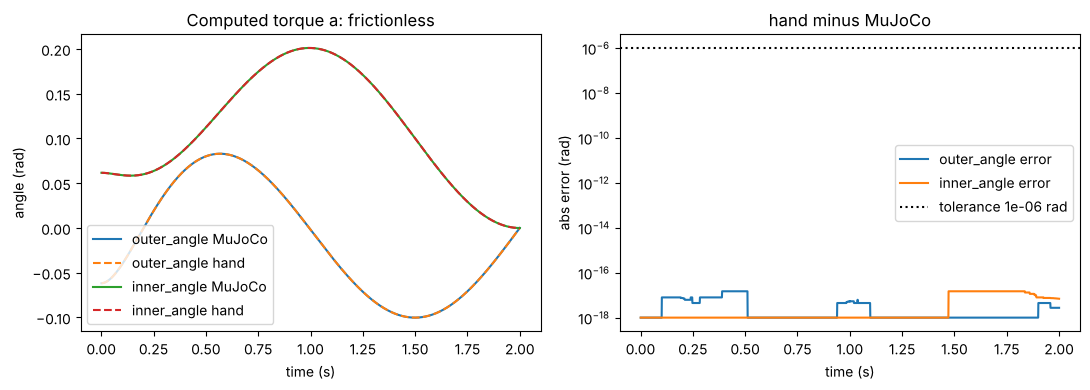

   hand tracking error vs analytic curve: max gap = 2.29e-04 rad (torque held constant over each step)
b: damping and friction (compensated): rows = 2000, max abs error = 7.48e-05 rad (tolerance 1e-03) PASS
   tracking error after 1 s: 1.87e-03 rad, largest |torque| = 2.293 N*m


saved the figure


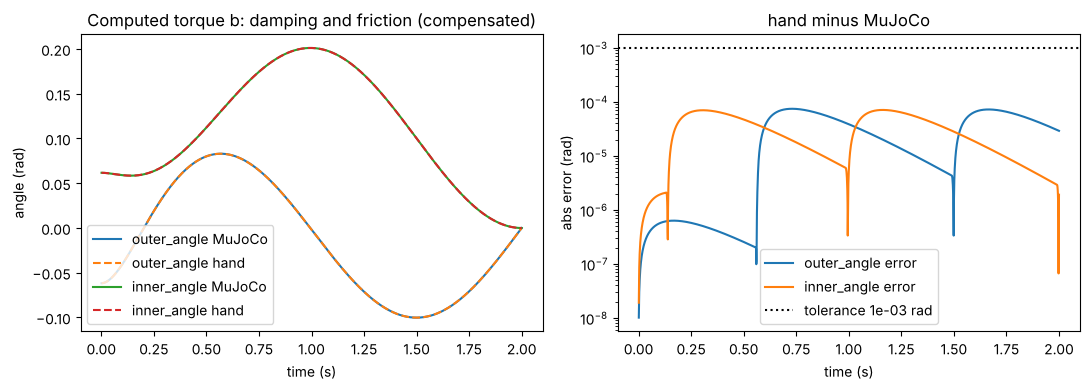

saved the data


In [9]:
# ─────────────────────────────────────────────
# STEP 8: computed torque tracking, hand plant and MuJoCo plant (equations 8.4 and 8.5)
# What we have: the reference circle, the controller above, two cases
# What we want: tracking error, comparison with MuJoCo, comparison with the analytic error curve
# Why: if tracking is good the hand model of M, h, g and friction is good
# ─────────────────────────────────────────────

N_STEPS = 2000
cases = [
    ("a: frictionless", 0.0, 0.0, 1e-6, "ct_case_a"),
    ("b: damping and friction (compensated)", VISCOUS_DAMPING_VALUE, COULOMB_FRICTION_VALUE, 1e-3, "ct_case_b"),
]  # (label, damping, friction, tolerance in rad, file stem), tolerances fixed before looking
saved_arrays = {}
for label, damping, friction, tolerance_rad, file_stem in cases:
    law = lambda angles, rates, step_index: computed_torque_command(angles, rates, step_index, damping, friction)
    hand_result = simulate(start_angles, start_rates, N_STEPS, damping, friction, law)
    mujoco_result = run_mujoco(start_angles, N_STEPS, damping, friction, law)  # MuJoCo plant, hand-model controller
    angle_error = compare_angles(hand_result, mujoco_result, tolerance_rad, label)
    time_axis = (np.arange(N_STEPS) + 1) * time_step
    reference = np.array([reference_at(t)[0] for t in time_axis])
    tracking_error = hand_result["angles"] - reference  # rad
    print(f"   tracking error after 1 s: {np.abs(tracking_error[1000:]).max():.2e} rad, largest |torque| = {np.abs(hand_result['motor_torque']).max():.3f} N*m")
    assert np.abs(hand_result["motor_torque"]).max() < motor_torque_limit, "torque saturated, equation 8.4 does not apply"
    plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, "Computed torque " + label, file_stem)
    saved_arrays[file_stem + "_angles"] = hand_result["angles"]
    saved_arrays[file_stem + "_reference"] = reference

    if file_stem == "ct_case_a":
        # equation 8.5: e(t) = (e0 + (e0_dot + wc e0) t) exp(-wc t), critically damped, wc = 6 1/s
        critical_frequency = np.sqrt(error_gain_p)
        initial_error = start_angles - reference_at(0.0)[0]
        initial_error_rate = start_rates - reference_at(0.0)[1]
        analytic_error = ((initial_error + (initial_error_rate + critical_frequency * initial_error) * time_axis[:, None])
                          * np.exp(-critical_frequency * time_axis)[:, None])
        analytic_gap = np.abs(tracking_error - analytic_error).max()
        print(f"   hand tracking error vs analytic curve: max gap = {analytic_gap:.2e} rad (torque held constant over each step)")
        assert analytic_gap < 1e-3

np.savez(os.path.join(RESULT_DIR, f"hand_computed_torque_{TIMESTAMP}.npz"), **saved_arrays)
print("saved the data")
